# C3 results: retrained vision arm, fusion arm and baselines

Everything here is read from saved evaluation files in `evidence/15_model_v3/`. Nothing is re-run, so the notebook opens instantly and every number can be traced to a file.

**How the numbers were produced**
- Threshold chosen on the **validation** set (424 screens), the **test** set (425 screens) scored **once** per model.
- Test screens are never trained on. Splits are grouped by app for Rico, and OwlEye screens were checked against near-duplicates.
- AUC is threshold-free. F1, precision and recall depend on the operating threshold, so read them together with the threshold sweep below.


In [1]:
import json, os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

C3 = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'evidence' / '15_model_v3').exists())
EV = C3 / 'evidence' / '15_model_v3'
FILES = {   # label -> (test scores file, validation scores file or None, fixed threshold or None)
    'v1 shipped (before)':        ('v1_on_v3test_scores.json', None, 0.5351),
    'v3 vision (retrained)':      ('v3_test_scores.json', 'v3_val_scores.json', None),
    'v3 fusion (+ layout text)':  ('v3_fusion_test_scores.json', 'v3_fusion_val_scores.json', None),
    'base, screenshot only':      ('base_vision_test_scores.json', None, 0.5),
    'base, + layout text':        ('base_fusion_test_scores.json', None, 0.5),
}
def load(name):
    p = EV / name
    return json.loads(p.read_text(encoding='utf-8')) if p.exists() else None
def recs(d):
    return [dict(p=float(r['p_defect']), gold=(r['gold_has'] is True or str(r['gold_has']).lower() == 'true'),
                 src='OwlEye' if 'OwlEye' in r['image'] else 'Rico', image=r['image'], gtype=r.get('gold_type')) for r in d['records']]
def auc(y, s):
    y, s = np.asarray(y, bool), np.asarray(s, float)
    pos, neg = s[y], s[~y]
    if len(pos) == 0 or len(neg) == 0: return float('nan')
    return float(((pos[:, None] > neg[None, :]) + 0.5 * (pos[:, None] == neg[None, :])).mean())
def boot_ci(y, s, n=1000, seed=0):
    rng = np.random.default_rng(seed); y, s = np.asarray(y, bool), np.asarray(s, float); out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); a = auc(y[i], s[i])
        if a == a: out.append(a)
    return np.percentile(out, [2.5, 97.5])
def at(rs, t):
    tp = sum(r['p'] >= t and r['gold'] for r in rs); fp = sum(r['p'] >= t and not r['gold'] for r in rs)
    fn = sum(r['p'] < t and r['gold'] for r in rs); tn = sum(r['p'] < t and not r['gold'] for r in rs)
    pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
    return dict(precision=pr, recall=rc, f1=2 * pr * rc / (pr + rc) if pr + rc else 0.0,
                false_alarm=fp / (fp + tn) if fp + tn else 0.0, accuracy=(tp + tn) / len(rs))
MODELS = {}
for label, (tf, vf, fixed) in FILES.items():
    t = load(tf)
    if t is None: continue
    thr = fixed if fixed is not None else (load(vf)['best_threshold']['threshold'] if vf and load(vf) else 0.5)
    MODELS[label] = dict(recs=recs(t), thr=thr)
print('models found:', list(MODELS))

models found: ['v1 shipped (before)', 'v3 vision (retrained)']


## 1. Headline comparison (test set, 425 screens)
The threshold for each model was fixed before looking at the test set: from validation for the retrained models, from the original selection for v1, and 0.5 for the untrained base.

In [2]:
rows = []
for label, m in MODELS.items():
    y = [r['gold'] for r in m['recs']]; s = [r['p'] for r in m['recs']]
    lo, hi = boot_ci(y, s); k = at(m['recs'], m['thr'])
    rows.append((label, m['thr'], auc(y, s), lo, hi, k['f1'], k['precision'], k['recall'], k['false_alarm']))
print(f"{'model':<28}{'thr':>6}{'AUC':>7}{'95% CI':>14}{'F1':>7}{'prec':>7}{'recall':>8}{'false alarms':>14}")
for r in rows:
    print(f"{r[0]:<28}{r[1]:>6.2f}{r[2]:>7.3f}   [{r[3]:.2f},{r[4]:.2f}]{r[5]:>7.3f}{r[6]:>7.2f}{r[7]:>8.2f}{r[8]:>14.0%}")

model                          thr    AUC        95% CI     F1   prec  recall  false alarms
v1 shipped (before)           0.54  0.735   [0.69,0.78]  0.707   0.65    0.78           51%
v3 vision (retrained)         0.30  0.814   [0.77,0.85]  0.775   0.68    0.90           50%


## 2. ROC curves
The curve shows every possible trade-off between catching defects and false alarms. The further up and to the left, the better the model separates defect from clean screens.

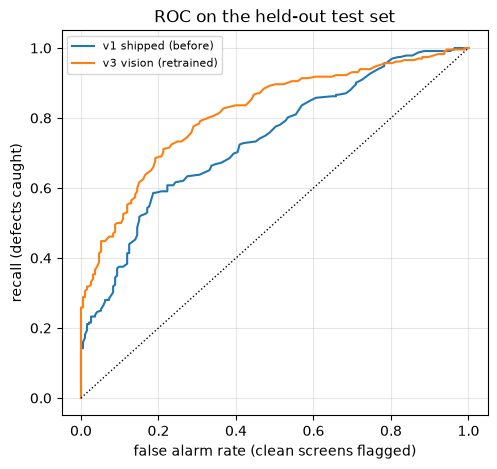

In [3]:
def roc(rs):
    y = np.array([r['gold'] for r in rs]); s = np.array([r['p'] for r in rs]); ts = np.unique(np.concatenate([[0, 1], s]))[::-1]
    return [(((s >= t) & ~y).sum() / (~y).sum(), ((s >= t) & y).sum() / y.sum()) for t in ts]
plt.figure(figsize=(5.5, 5))
for label, m in MODELS.items():
    pts = np.array(roc(m['recs'])); plt.plot(pts[:, 0], pts[:, 1], label=label)
plt.plot([0, 1], [0, 1], 'k:', lw=1); plt.xlabel('false alarm rate (clean screens flagged)'); plt.ylabel('recall (defects caught)')
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.title('ROC on the held-out test set'); plt.show()

## 3. Why recall is high: the threshold sweep (retrained vision arm)
Recall and false alarms move together as the threshold changes. The chosen operating point favours catching defects.

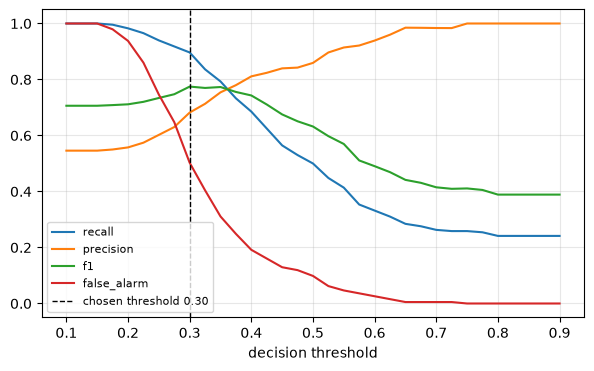

threshold 0.30: precision 0.68, recall 0.90, f1 0.77, false_alarm 0.50, accuracy 0.72
threshold 0.40: precision 0.81, recall 0.69, f1 0.74, false_alarm 0.19, accuracy 0.74
threshold 0.50: precision 0.86, recall 0.50, f1 0.63, false_alarm 0.10, accuracy 0.68


In [4]:
m = MODELS['v3 vision (retrained)']; ts = np.linspace(0.1, 0.9, 33)
ks = [at(m['recs'], t) for t in ts]
plt.figure(figsize=(7, 4))
for key in ('recall', 'precision', 'f1', 'false_alarm'): plt.plot(ts, [k[key] for k in ks], label=key)
plt.axvline(m['thr'], color='k', ls='--', lw=1, label=f"chosen threshold {m['thr']:.2f}"); plt.xlabel('decision threshold'); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()
for t in (m['thr'], 0.4, 0.5): k = at(m['recs'], t); print(f"threshold {t:.2f}: " + ', '.join(f'{a} {v:.2f}' for a, v in k.items()))

## 4. Score distributions
If scores for defect and clean screens were piled at 0 and 1, that would suggest memorisation or leakage. Here the two groups overlap, which is what a moderate, honest model looks like.

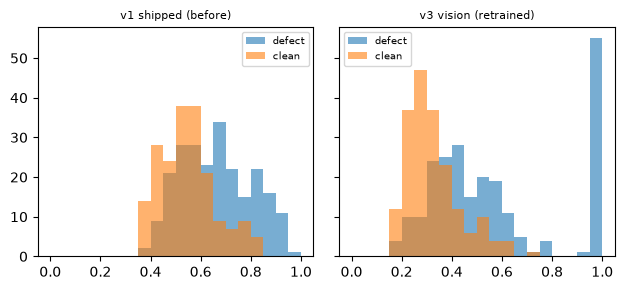

In [5]:
fig, ax = plt.subplots(1, len(MODELS), figsize=(3.2 * len(MODELS), 3), sharey=True, squeeze=False)
for a, (label, m) in zip(ax[0], MODELS.items()):
    a.hist([r['p'] for r in m['recs'] if r['gold']], bins=20, range=(0, 1), alpha=.6, label='defect')
    a.hist([r['p'] for r in m['recs'] if not r['gold']], bins=20, range=(0, 1), alpha=.6, label='clean'); a.set_title(label, fontsize=8); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. By data source and defect type (retrained vision arm)

In [6]:
m = MODELS['v3 vision (retrained)']
for src in ('OwlEye', 'Rico'):
    sub = [r for r in m['recs'] if r['src'] == src]; k = at(sub, m['thr'])
    print(f"{src:<7} n={len(sub):<4} AUC {auc([r['gold'] for r in sub], [r['p'] for r in sub]):.3f}  F1 {k['f1']:.2f}  recall {k['recall']:.2f}  false alarms {k['false_alarm']:.0%}")
print()
for t in ('component_overlap', 'data_binding_null', 'missing_component', 'text_truncation'):
    sub = [r for r in m['recs'] if r['gtype'] == t]
    print(f"{t:<20} n={len(sub):<4} caught {sum(r['p'] >= m['thr'] for r in sub) / len(sub):.0%}   mean score {np.mean([r['p'] for r in sub]):.2f}")

OwlEye  n=165  AUC 0.828  F1 0.77  recall 0.90  false alarms 45%
Rico    n=260  AUC 0.803  F1 0.78  recall 0.89  false alarms 55%

component_overlap    n=67   caught 82%   mean score 0.38
data_binding_null    n=57   caught 100%   mean score 0.98
missing_component    n=63   caught 90%   mean score 0.49
text_truncation      n=45   caught 87%   mean score 0.46


## 6. Leakage and sanity checks
1. Train and test AUC are about the same, so the model is not memorising training screens.
2. No image is shared between splits, and no Rico source screen appears in more than one split.
3. Removing test screens that have a near-duplicate in train barely changes the test AUC.

In [7]:
tr = load('train200_scores.json'); sc = load('spot_check/spot_check.json')
if tr: print(f"AUC on 200 TRAINING screens: {tr['auc']}  (95% CI {tr['auc_95ci']})   vs  TEST: {MODELS['v3 vision (retrained)'] and round(auc([r['gold'] for r in MODELS['v3 vision (retrained)']['recs']], [r['p'] for r in MODELS['v3 vision (retrained)']['recs']]), 3)}")
if sc:
    L = sc['leakage']
    print('shared images between splits   :', L['shared_images'])
    print('Rico source screens in 2 splits:', L['rico_source_overlap'])
    print('OwlEye train&test near-duplicate pairs:', L['owleye_near_duplicates']['train&test'])
    print(f"test AUC {L['test_auc_all']} -> without the {L['test_screens_dropped']} near-duplicate screens {L['test_auc_without_near_duplicates']}")

AUC on 200 TRAINING screens: 0.7738  (95% CI [0.7037, 0.833])   vs  TEST: 0.814
shared images between splits   : {'train&val': 0, 'train&test': 0, 'val&test': 0}
Rico source screens in 2 splits: {'train&val': 0, 'train&test': 0, 'val&test': 0}
OwlEye train&test near-duplicate pairs: {'pairs': 15, 'by_kind': {'bug-normal': 5, 'normal-bug': 5, 'normal-normal': 5}}
test AUC 0.8135 -> without the 12 near-duplicate screens 0.8096


## 7. Localization (box overlap) on 122 test defects
The model finds the right area of the screen but does not draw tight boxes. IoU 0.5 means the predicted and true boxes overlap by half.

In [8]:
def box(v): return json.loads(v) if isinstance(v, str) else v
def iou1(a0, a1, b0, b1):
    i = max(0, min(a1, b1) - max(a0, b0)); u = (a1 - a0) + (b1 - b0) - i; return i / u if u > 0 else 0
E2E = {'v3 vision': 'v3_e2e_defects122.json', 'v3 fusion': 'v3_fusion_e2e_defects122.json'}
for label, f in E2E.items():
    d = load(f)
    if not d: continue
    s = d['summary']; print(f"== {label}: defects flagged {s['tp']}/{s['n']}, type correct {s['type_accuracy_on_defects']:.0%}, IoU>=0.5 {s['iou_at_0_5_on_defects']:.1%}")
    for src in ('OwlEye', 'Rico'):
        sub = [r for r in d['records'] if (('OwlEye' in r['image']) == (src == 'OwlEye'))]
        i = [float(r['iou'] or 0) for r in sub]
        pairs = [(box(r['pred_box']), box(r['gold_box'])) for r in sub if r['pred_box'] and r['gold_box']]
        cy = [abs((p[0] + p[2]) / 2 - (g[0] + g[2]) / 2) for p, g in pairs]
        print(f"   {src:<7} n={len(sub):<3} mean IoU {np.mean(i):.2f}  IoU>=0.5 {np.mean([x >= .5 for x in i]):.1%}  IoU>=0.3 {np.mean([x >= .3 for x in i]):.1%}  median vertical centre error {np.median(cy):.0f}/1000")

== v3 vision: defects flagged 110/122, type correct 65%, IoU>=0.5 6.6%
   OwlEye  n=82  mean IoU 0.06  IoU>=0.5 1.2%  IoU>=0.3 6.1%  median vertical centre error 49/1000
   Rico    n=40  mean IoU 0.21  IoU>=0.5 17.5%  IoU>=0.3 22.5%  median vertical centre error 43/1000


Random screens with the true box (green) and the model's box (red), p = model's defect score:

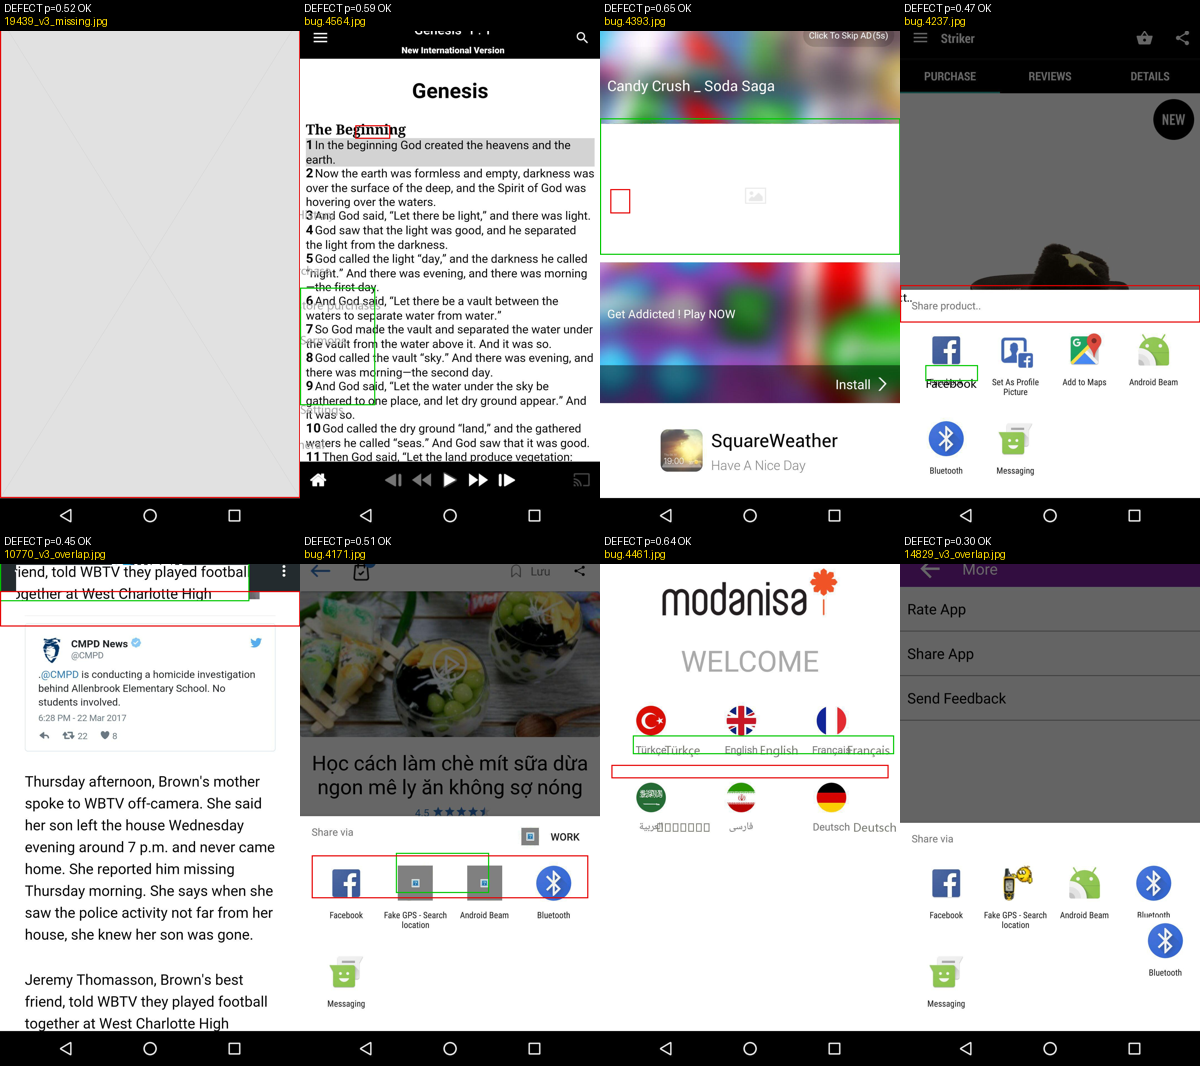

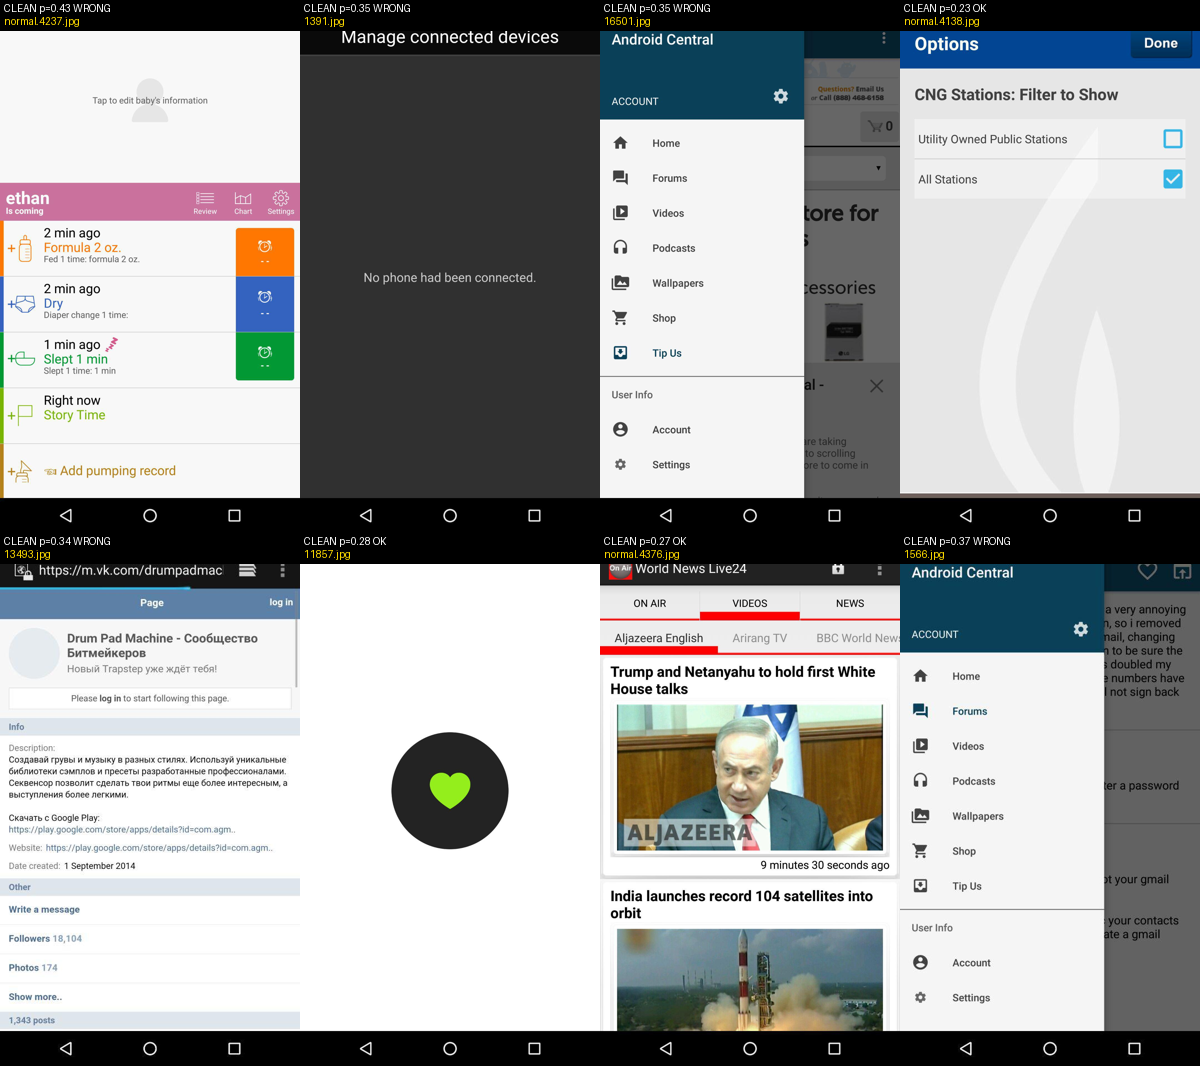

In [9]:
from IPython.display import Image as Img, display
for f in ('spot_defect_screens.png', 'spot_clean_screens.png'):
    p = EV / 'spot_check' / f
    if p.exists(): display(Img(filename=str(p), width=900))

## 8. Training curve and dataset
Loss falls from 0.43 to about 0.30 and then flattens. Loss measures how well the model reproduces the answer text. It is not detection accuracy.

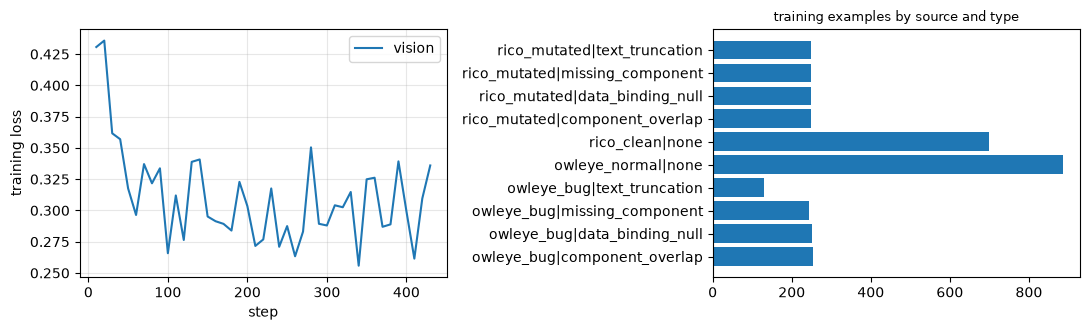

training examples: 3466


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for label, f in (('vision', 'v3_vision_trainer_log.jsonl'), ('fusion', 'v3_fusion_trainer_log.jsonl')):
    p = EV / f
    if p.exists():
        rows = [json.loads(l) for l in p.read_text(encoding='utf-8').splitlines() if l.strip()]
        ax[0].plot([r['current_steps'] for r in rows if 'loss' in r], [r['loss'] for r in rows if 'loss' in r], label=label)
ax[0].set_xlabel('step'); ax[0].set_ylabel('training loss'); ax[0].legend(); ax[0].grid(alpha=.3)
rep = json.loads((C3 / 'evidence' / '12_dataset_v3' / 'dataset_v3_report.json').read_text(encoding='utf-8'))['splits']['train']
names, vals = list(rep), list(rep.values()); ax[1].barh(names, vals); ax[1].set_title('training examples by source and type', fontsize=9); plt.tight_layout(); plt.show()
print('training examples:', sum(vals))

## 9. What this does and does not show
- Detection improved measurably: AUC 0.735 to 0.814, with confidence intervals that do not overlap the old model's value.
- Defect-type accuracy on flagged defects roughly doubled.
- At the chosen threshold about half of clean screens are flagged. In real use defects are rare, so precision would be lower than shown here. Reducing false alarms is future work.
- Boxes are in the right area but rarely tight. Real OwlEye bugs have no layout files, so the fusion effect can only be measured on the synthetic Rico screens.
- One epoch, one seed, model-assisted labels. These are limits, not hidden details.
